# 01 · Auditoría y preparación de las muestras

**Proyecto final · Machine Learning 1 · FIUNA · 2026**  
**Tema:** clasificación del estado registrado de roya asiática de la soja a partir de variables meteorológicas.

### Objetivo
Antes de entrenar los modelos, verificamos de dónde provienen los datos, qué significan las etiquetas, cómo se forman las muestras y si las particiones temporales evitan solapamientos.

**Dos tareas del proyecto:**
- **h0:** clasificar el resultado registrado en la fecha de referencia `t`.
- **h7:** clasificar el resultado registrado exactamente siete días después, en `t+7`.

En ambos casos utilizamos variables meteorológicas agregadas de los **7 o 14 días anteriores a `t`**. Los días de una ventana son observaciones meteorológicas, no muestras independientes.

> **Alcance:** este notebook audita productos ya generados por `scripts/procesar_datos.py`. No descarga datos, no reconstruye respuestas horarias y no entrena modelos. Los resultados originales individuales se mantienen locales y no se muestran coordenadas ni identificadores personales.

**Ejecución:** abrir el notebook desde `notebooks/` o desde la raíz del repositorio, con los archivos locales de `data/` y las dependencias del proyecto. Una copia pública sin los insumos originales no permite volver a ejecutar toda la auditoría.

## 1. Librerías y carga de datos

Utilizamos `pandas` y `numpy` para revisar los datos, y `matplotlib` para una visualización básica. Importamos del script de preparación únicamente las reglas que deben coincidir con el procesamiento oficial.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localizar la raíz del proyecto, independientemente de dónde se abra Jupyter.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "proyecto.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abrí el notebook desde la carpeta del proyecto.")

sys.path.insert(0, str(ROOT / "scripts"))
from procesar_datos import (
    FEATURES, AGGREGATIONS, configured, observations,
    verify_samples, check_separation,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 25)

def leer_json(ruta):
    return json.loads(ruta.read_text(encoding="utf-8"))

In [2]:
original = pd.read_csv(configured("original"), dtype={"latitud": str, "longitud": str})
observadas = pd.read_csv(configured("datos") / "observaciones.csv", dtype={"latitud": str, "longitud": str})
muestras = pd.read_csv(configured("datos") / "muestras.csv", dtype={"latitud": str, "longitud": str})
diarios = pd.read_csv(configured("intermedios") / "diarios_reconstruidos.csv")
exclusiones = pd.read_csv(configured("datos") / "exclusiones.csv")
particiones = leer_json(configured("datos") / "particiones.json")
resumen = pd.read_csv(configured("datos") / "resumen_particiones.csv", dtype={"bloque": str})
traza = leer_json(configured("intermedios") / "traza.json")

display(pd.DataFrame({
    "fuente": ["Resultados originales", "Respuestas meteorológicas", "Filas meteorológicas diarias", "Filas de muestras"],
    "cantidad": [len(original), len(traza["respuestas"]), len(diarios), len(muestras)],
    "unidad": ["registros", "archivos", "filas", "filas (incluyen ambas ventanas)"],
}))

,fuente,cantidad,unidad
0,Resultados originales,650,registros
1,Respuestas meteorológicas,66,archivos
2,Filas meteorológicas diarias,5992,filas
3,Filas de muestras,1580,filas (incluyen ambas ventanas)


### Procedencia y unidad de observación

- **Etiquetas:** Epagri/CIRAM Agroconnect (`busca-doenca-munic.jsp`), a partir de registros de monitoreo deduplicados.
- **Meteorología:** respuestas horarias Open-Meteo/ERA5, agregadas por día local (`America/Sao_Paulo`, UTC−3).
- **Observación original:** resultado registrado para una ubicación y fecha.
- **Muestra para ML:** una observación evaluable con una ventana meteorológica y una etiqueta h0 o h7.

La meteorología ERA5 es una reconstrucción espacial retrospectiva, no una medición en la parcela. La atribución meteorológica se rige por [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); las condiciones de redistribución de las etiquetas aún requieren aclaración.

## 2. Estructura y calidad de los datos originales

Como en los trabajos prácticos de ML1, primero inspeccionamos columnas, tipos, valores faltantes y fechas. Los campos auxiliares sin documentación no se consideran predictores.

In [3]:
estructura = pd.DataFrame({
    "tipo": original.dtypes.astype(str),
    "faltantes": original.isna().sum(),
    "faltantes_%": original.isna().mean().mul(100).round(1),
    "valores_distintos": original.nunique(dropna=True),
})
display(estructura)

fechas = original[["fecha_registro", "primera_consulta", "ultima_consulta"]].apply(pd.to_datetime)
display(pd.DataFrame({"fecha_mínima": fechas.min(), "fecha_máxima": fechas.max()}))

# Vista de ejemplo sin coordenadas ni identificadores individuales.
display(original[["fecha_registro", "clase_original", "n_snapshots"]].head())

,tipo,faltantes,faltantes_%,valores_distintos
punto_id,int64,0,0.0,23
punto_nombre,object,0,0.0,23
longitud,object,0,0.0,22
latitud,object,0,0.0,22
clase_codigo,int64,0,0.0,3
clase_original,object,0,0.0,3
municipio,object,0,0.0,22
fecha_registro,object,0,0.0,48
campo_8_original,int64,0,0.0,1
campo_9_original,int64,0,0.0,22


,fecha_mínima,fecha_máxima
fecha_registro,2024-09-02,2026-03-02
primera_consulta,2024-09-02,2026-03-02
ultima_consulta,2024-09-08,2026-07-31


,fecha_registro,clase_original,n_snapshots
0,2024-09-02,Positivo,7
1,2024-09-02,Negativo,7
2,2024-09-02,Negativo,7
3,2024-09-02,Negativo,7
4,2024-09-02,Não Avaliado,7


**Interpretación:** el tipo mostrado por `pandas` representa el formato leído del CSV. Que una fecha esté bien formada no demuestra que sea la fecha de muestreo. Tampoco asumimos un significado agronómico para `campo_8_original` ni `campo_9_original`.

## 3. Duplicados e identidad de las observaciones

La ubicación se identifica provisionalmente por las coordenadas originales sin redondeos que unan puntos distintos. Dos IDs con las mismas coordenadas no prueban que sean la misma parcela física.

In [4]:
# Comprobación de que la reconstrucción de identidades coincide con el archivo procesado.
reconstruidas = observations(original)
assert reconstruidas.observacion_id.tolist() == observadas.observacion_id.tolist()

controles = {
    "Registros originales": len(original),
    "Duplicados exactos": int(original.duplicated().sum()),
    "Duplicados ubicación-fecha": int(observadas.duplicated(["ubicacion_id", "fecha_registro"]).sum()),
    "Conflictos declarados": int(original.conflicto_clase_mismo_punto_fecha.sum()),
    "IDs de punto": original.punto_id.nunique(),
    "Ubicaciones por coordenadas": observadas.ubicacion_id.nunique(),
    "Ubicaciones con varios IDs de punto": int(
        observadas.groupby("ubicacion_id").punto_id.nunique().gt(1).sum()
    ),
    "fecha_registro = primera_consulta": int(
        fechas.fecha_registro.eq(fechas.primera_consulta).sum()
    ),
}
display(pd.Series(controles, name="resultado").to_frame())
display(observadas.estado.value_counts().rename_axis("estado").to_frame("registros"))

,resultado
Registros originales,650
Duplicados exactos,0
Duplicados ubicación-fecha,0
Conflictos declarados,0
IDs de punto,23
Ubicaciones por coordenadas,22
Ubicaciones con varios IDs de punto,1
fecha_registro = primera_consulta,650


,registros
estado,
evaluado,428
no_evaluado,222


**Interpretación:** `fecha_registro` se utiliza como fecha del resultado registrado, **no como fecha de muestreo comprobada**. La coincidencia de coordenadas tampoco resuelve la identidad física de los lotes.

## 4. Variable objetivo: estados y etiquetas

La fuente distingue los estados **79 = Positivo**, **80 = Negativo** y **82 = Não Avaliado**. Para ML utilizamos `1` para positivo y `0` para negativo. Un resultado **Não Avaliado no es un negativo**, por lo que se excluye de las muestras etiquetadas.

Un positivo registrado puede reflejar una primera detección o un estado positivo posterior: no equivale automáticamente a una infección nueva.

,clase_codigo,clase_original,registros,porcentaje
0,79,Positivo,211,32.5
1,80,Negativo,217,33.4
2,82,Não Avaliado,222,34.2


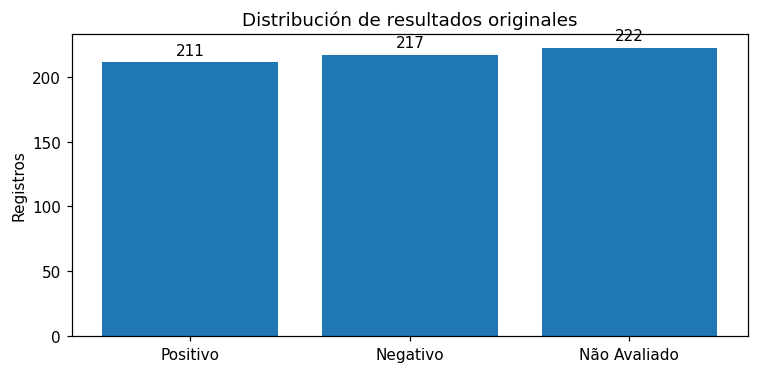

In [5]:
clases = (original.groupby(["clase_codigo", "clase_original"])
          .size().rename("registros").reset_index())
clases["porcentaje"] = (100 * clases.registros / len(original)).round(1)
display(clases)

fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(clases.clase_original, clases.registros)
ax.bar_label(barras, padding=3)
ax.set(title="Distribución de resultados originales", ylabel="Registros")
plt.tight_layout()
plt.show()

**Interpretación:** esta distribución describe **todos los resultados originales**, antes de filtrar las muestras para h0 y h7. El equilibrio global no garantiza que cada período o conjunto de entrenamiento tenga la misma proporción de clases.

## 5. Variables meteorológicas y cobertura

Cada medición debe tener 14 días meteorológicos anteriores (`t−14` a `t−1`). Se construyen dos ventanas, de 7 y 14 días, con las mismas diez variables. La precipitación se suma; otras variables usan media, mínimo o máximo según su definición.

Para el viento, las componentes se calculan según la dirección meteorológica de procedencia: \(u=-v\sin(\theta)\) y \(v_N=-v\cos(\theta)\). Un valor negativo de componente expresa dirección.

In [6]:
unidades = ["%"] * 3 + ["°C"] * 3 + ["mm"] + ["m/s"] * 3
display(pd.DataFrame({
    "variable": FEATURES,
    "unidad": unidades,
    "agregación": [AGGREGATIONS[x] for x in FEATURES],
}))

cobertura = diarios.groupby("id_medicion").dias_anteriores.agg(["count", "min", "max"])
assert cobertura["count"].eq(14).all()
assert cobertura["min"].eq(1).all() and cobertura["max"].eq(14).all()
assert np.isfinite(diarios[FEATURES].to_numpy()).all()

separacion_fechas = (
    pd.to_datetime(diarios.fecha_objetivo) - pd.to_datetime(diarios.fecha_dato)
).dt.days
assert separacion_fechas.eq(diarios.dias_anteriores).all()

display(pd.Series({
    "Mediciones con 14 días completos": len(cobertura),
    "Filas meteorológicas diarias": len(diarios),
    "Faltantes en las diez variables": int(diarios[FEATURES].isna().sum().sum()),
    "Variables predictoras": len(FEATURES),
    "Menor desfase (días)": int(diarios.dias_anteriores.min()),
    "Mayor desfase (días)": int(diarios.dias_anteriores.max()),
}, name="resultado").to_frame())

,variable,unidad,agregación
0,hr_media_pct,%,mean
1,hr_min_pct,%,min
2,hr_max_pct,%,max
3,temperatura_media_c,°C,mean
4,temperatura_min_c,°C,min
5,temperatura_max_c,°C,max
6,precipitacion_mm,mm,sum
7,viento_vel_media_10m_ms,m/s,mean
8,viento_u_media_10m_ms,m/s,mean
9,viento_v_media_10m_ms,m/s,mean


,resultado
Mediciones con 14 días completos,428
Filas meteorológicas diarias,5992
Faltantes en las diez variables,0
Variables predictoras,10
Menor desfase (días),1
Mayor desfase (días),14


**Interpretación:** los predictores se calculan únicamente con meteorología **anterior a `t`**. No incorporan el clima del propio día `t` ni el período futuro hasta `t+7`. No se dispone de horas de mojado foliar como predictor de estos experimentos.

## 6. Construcción de las muestras h0 y h7

Las muestras ya fueron construidas mediante `procesar_datos.py`; aquí verificamos sus reglas sin generar archivos nuevos.

- **h0:** la etiqueta es el estado evaluado en `t`.
- **h7:** la etiqueta es el estado evaluado exactamente en `t+7`, en la misma ubicación. Se exige además un resultado evaluado en `t`.
- **Ventanas:** cada objetivo elegible tiene dos filas de características (7 y 14 días), pero sigue siendo un solo objetivo.

In [7]:
verify_samples(muestras)

poblacion = (muestras.groupby(["horizonte_dias", "ventana_dias"])
             .agg(muestras=("muestra_id", "nunique"),
                  negativos=("y", lambda s: int(s.eq(0).sum())),
                  positivos=("y", "sum"),
                  ubicaciones=("ubicacion_id", "nunique")))
display(poblacion)

dias_hasta_etiqueta = (
    pd.to_datetime(muestras.fecha_objetivo) - pd.to_datetime(muestras.fecha_referencia)
).dt.days
assert dias_hasta_etiqueta.eq(muestras.horizonte_dias).all()
assert muestras.groupby("muestra_id").ventana_dias.apply(lambda x: set(x) == {7, 14}).all()

print("Muestras independientes por horizonte:")
display(muestras.groupby("horizonte_dias").muestra_id.nunique().rename("muestras"))

muestras  negativos  positivos  ubicaciones
horizonte_dias ventana_dias                                             
0              7                  428        217        211           22
               14                 428        217        211           22
7              7                  362        179        183           22
               14                 362        179        183           22

Muestras independientes por horizonte:


horizonte_dias
0    428
7    362
Name: muestras, dtype: int64

**Interpretación:** las filas con ventanas de 7 y 14 días representan alternativas de predictores para una misma etiqueta. No deben sumarse como si fueran observaciones independientes. Además, h0 y h7 tienen poblaciones diferentes por sus requisitos de etiqueta.

## 7. Exclusiones y límites de la predicción futura

Contamos una exclusión por observación y horizonte, no por ventana. La falta de una evaluación en `t+7` no indica ausencia de roya.

También examinamos, **solo descriptivamente**, el subconjunto h7 cuyo estado de partida en `t` era negativo. Ese subconjunto no reemplaza el experimento oficial.

In [8]:
display(exclusiones.groupby(["horizonte_dias", "motivo"])
        .size().rename("exclusiones").to_frame())

h7 = muestras.query("horizonte_dias == 7 and ventana_dias == 7")
h7_desde_negativo = h7[h7.resultado_t.eq(0)]
display(pd.DataFrame({
    "población": ["h7 completo", "h7 desde negativo en t (auxiliar)"],
    "muestras": [len(h7), len(h7_desde_negativo)],
    "negativos_en_t+7": [int(h7.y.eq(0).sum()), int(h7_desde_negativo.y.eq(0).sum())],
    "positivos_en_t+7": [int(h7.y.eq(1).sum()), int(h7_desde_negativo.y.eq(1).sum())],
}))

exclusiones
horizonte_dias motivo                             
0              referencia_no_evaluado          222
7              objetivo_no_evaluado             56
               objetivo_sin_registro            10
               referencia_no_evaluado          222

,población,muestras,negativos_en_t+7,positivos_en_t+7
0,h7 completo,362,179,183
1,h7 desde negativo en t (auxiliar),188,131,57


**Interpretación:** h7 estima el **estado registrado futuro**, no necesariamente la aparición de una infección nueva. Su población incluye observaciones positivas en `t`, y los casos sin registro exactamente siete días después quedan fuera.

## 8. Separación temporal y control de solapamiento

En series temporales no es apropiado mezclar indiscriminadamente observaciones pasadas y futuras. Utilizamos las particiones oficiales de `particiones.json`, organizadas en bloques cronológicos. Los predictores se basan en hasta 14 días anteriores, por lo que se verifica la **purga temporal** entre entrenamiento y validación.

La evaluación enero–marzo de 2026 es **histórica y previamente observada**, no una prueba inédita. La mostramos para documentar la estrategia, sin utilizarla para elegir variables ni parámetros.

In [9]:
columnas = ["horizonte", "bloque", "rol", "n", "negativos", "positivos",
            "ubicaciones", "etiqueta_inicio", "etiqueta_fin", "dias_inclusivos", "fechas_observadas"]
display(resumen[columnas].fillna("—"))

comprobaciones = []
for horizonte in [0, 7]:
    # Solo una ventana, para no duplicar las muestras.
    datos = muestras.query("horizonte_dias == @horizonte and ventana_dias == 14")
    datos = datos.set_index("muestra_id", drop=False)
    for bloque in ["1", "2", "3", "historico"]:
        division = particiones[str(horizonte)][bloque]
        entrenamiento = datos.loc[division["train_ids"]]
        validacion = datos.loc[division["validation_ids"]]
        check_separation(entrenamiento, validacion)

        ultima_etiqueta = pd.to_datetime(entrenamiento.fecha_objetivo).max()
        primera_referencia = pd.to_datetime(validacion.fecha_referencia).min()
        margen = (primera_referencia - ultima_etiqueta).days
        purga = ultima_etiqueta < primera_referencia - pd.Timedelta(days=14)
        assert purga

        comprobaciones.append({
            "horizonte": horizonte,
            "bloque": bloque,
            "última_etiqueta_train": ultima_etiqueta.date(),
            "primera_referencia_valid": primera_referencia.date(),
            "separación_días": margen,
            "purga_14_días": purga,
        })

display(pd.DataFrame(comprobaciones))

,horizonte,bloque,rol,n,negativos,positivos,ubicaciones,etiqueta_inicio,etiqueta_fin,dias_inclusivos,fechas_observadas
0,0,historico,entrenamiento,359,188.0,171.0,22.0,2024-09-02,2025-12-15,470.0,37.0
1,0,historico,evaluacion_historica,66,29.0,37.0,12.0,2026-01-05,2026-03-02,57.0,9.0
2,0,historico,purga,3,0.0,3.0,3.0,2025-12-22,2025-12-22,1.0,1.0
3,0,1,entrenamiento,164,78.0,86.0,17.0,2024-09-02,2025-01-06,127.0,18.0
4,0,1,validacion,38,23.0,15.0,8.0,2025-08-18,2025-09-22,36.0,6.0
5,0,1,purga,2,2.0,0.0,2.0,2025-08-11,2025-08-11,1.0,1.0
6,0,2,entrenamiento,188,95.0,93.0,17.0,2024-09-02,2025-09-08,372.0,23.0
7,0,2,validacion,55,29.0,26.0,12.0,2025-09-29,2025-11-03,36.0,6.0
8,0,2,purga,16,8.0,8.0,8.0,2025-09-15,2025-09-22,8.0,2.0
9,0,3,entrenamiento,239,120.0,119.0,18.0,2024-09-02,2025-10-20,414.0,29.0


,horizonte,bloque,última_etiqueta_train,primera_referencia_valid,separación_días,purga_14_días
0,0,1,2025-01-06,2025-08-18,224,True
1,0,2,2025-09-08,2025-09-29,21,True
2,0,3,2025-10-20,2025-11-10,21,True
3,0,historico,2025-12-15,2026-01-05,21,True
4,7,1,2024-12-23,2025-08-11,231,True
5,7,2,2025-09-01,2025-09-22,21,True
6,7,3,2025-10-13,2025-11-03,21,True
7,7,historico,2025-12-15,2026-01-05,21,True


**Interpretación:** la purga evita que se reutilicen períodos meteorológicos solapados entre los roles comprobados. Este diseño evalúa principalmente **transferencia temporal**: una misma ubicación puede aparecer en entrenamiento y evaluación. Por lo tanto, no demuestra generalización a parcelas completamente nuevas. Tampoco acredita que las etiquetas hubieran estado disponibles operativamente en la fecha necesaria.

## 9. Conclusiones de la auditoría

1. **Fuentes:** los resultados de monitoreo y el clima retrospectivo provienen de fuentes diferentes; la identidad física y la fecha de muestreo no están completamente acreditadas.
2. **Etiquetas:** solamente `Positivo` y `Negativo` constituyen clases para ML. `Não Avaliado` no se interpreta como ausencia de enfermedad.
3. **Predictores:** se utilizan diez variables meteorológicas y ventanas anteriores de 7 o 14 días, sin incorporar datos meteorológicos posteriores a la referencia.
4. **Horizontes:** h0 y h7 son tareas distintas, y h7 requiere una evaluación en la fecha exacta `t+7`.
5. **Validación:** las particiones se definieron temporalmente y se comprueba una purga para evitar solapamiento entre entrenamiento y validación.

**Siguiente paso:** el notebook `02_exploracion.ipynb` analiza distribuciones, relaciones entre variables y diferencias entre clases, restringiendo las decisiones exploratorias a los datos de desarrollo.

> Esta auditoría comprueba coherencia técnica de los datos procesados. No equivale a una validación agronómica ni a una evaluación prospectiva en condiciones reales.